# Second-Crop Experiment: the same four MobileNet models on another plant (PlantVillage)

The thesis title covers **plant** leaf disease, but the main experiments use cotton only. This notebook repeats the **same leak-free, five-seed experiment** on a second crop from the public PlantVillage dataset (default: **potato**, 3 classes, about 2,150 images). It uses exactly the same models, seeds, schedule, learning rates, dropout and CBAM settings as `Multi_seeds_models_leakfree.ipynb`, so the results can be reported as a generalisation check in the thesis.

**Before you start:** Runtime > Change runtime type > **T4 GPU**. Then Runtime > **Run all**. It takes roughly 1 to 1.5 hours and resumes after a disconnect (finished runs are skipped).

Note for the thesis: PlantVillage images were taken in a lab on a plain background, so accuracy is usually very high (around 99%). Say this when you report it.

In [1]:
# STEP 0 - Mount Drive and settings (edit only this cell)
from google.colab import drive
drive.mount('/content/drive')

import os
CROP_PREFIX = "Potato___"   # PlantVillage crop to use: "Potato___" (3 classes, fast) or "Tomato___" (10 classes, ~4x slower)
OUT_DIR    = "/content/drive/MyDrive/MSAmber/second_crop_" + CROP_PREFIX.strip("_").lower()   # results for this crop
LOCAL_DATA = "/content/data_" + CROP_PREFIX.strip("_").lower()     # images are exported here (train/val/test)

SEEDS  = [42, 123, 202, 456, 789]
MODELS = ["mobilenetv2", "mobilenetv2_cbam", "mobilenetv1", "mobilenetv3large"]   # all four, so Table 4.5 can be replaced too

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
INITIAL_EPOCHS = 10
FINE_TUNE_EPOCHS = 5
INITIAL_LR = 1e-4
FINE_TUNE_LR = 1e-5
DROPOUT = 0.3
CBAM_RATIO = 8
CBAM_KERNEL = 7

DETERMINISTIC = True     # set False if TensorFlow raises a "no deterministic implementation" error
RUN_LEAKAGE_CHECK = True
REMOVE_LEAKED = True     # drop training images that are copies (flipped/rotated/edited) of a val or test image
LEAK_THRESHOLD = 4       # perceptual-hash distance counted as "same image"

os.makedirs(OUT_DIR, exist_ok=True)

Mounted at /content/drive


## Step 1: Download PlantVillage and build a 70 / 15 / 15 split (one time per session)
Downloads only the chosen crop's folders of the public PlantVillage dataset from its GitHub mirror (spMohanty/PlantVillage-Dataset, colour images; no account needed), then writes a stratified 70% / 15% / 15% train / val / test split with a fixed random seed (0). No augmentation is added.

In [2]:
import time, shutil, glob, numpy as np
SRC = "/content/plantvillage_src"
if not os.path.exists(os.path.join(LOCAL_DATA, "test")):
    t0 = time.time()
    if not os.path.exists(SRC):
        import subprocess
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse",
                        "https://github.com/spMohanty/PlantVillage-Dataset", SRC], check=True)
        subprocess.run(["git", "-C", SRC, "sparse-checkout", "set", "--no-cone", f"raw/color/{CROP_PREFIX}*"], check=True)
    class_dirs = sorted(d for d in glob.glob(os.path.join(SRC, "raw", "color", CROP_PREFIX + "*")) if os.path.isdir(d))
    assert class_dirs, f"No PlantVillage folders start with {CROP_PREFIX!r}; check the download above"
    rng = np.random.default_rng(0)
    for cdir in class_dirs:
        cls = os.path.basename(cdir)[len(CROP_PREFIX):].replace("_", " ").strip()
        files = sorted(f for f in os.listdir(cdir) if f.lower().endswith((".jpg", ".jpeg", ".png")))
        idx = rng.permutation(len(files))
        n_tr, n_va = int(0.70 * len(files)), int(0.15 * len(files))
        parts = {"train": idx[:n_tr], "val": idx[n_tr:n_tr + n_va], "test": idx[n_tr + n_va:]}
        for split, ids in parts.items():
            d = os.path.join(LOCAL_DATA, split, cls); os.makedirs(d, exist_ok=True)
            for k in ids:
                shutil.copy(os.path.join(cdir, files[k]), os.path.join(d, files[k]))
    print(f"Downloaded and split in {(time.time()-t0)/60:.1f} min")
for split in ["train", "val", "test"]:
    counts = {c: len(os.listdir(os.path.join(LOCAL_DATA, split, c))) for c in sorted(os.listdir(os.path.join(LOCAL_DATA, split)))}
    print(f"{split:5s}: {sum(counts.values()):5d}  {counts}")

Downloaded and split in 0.1 min
train:  1506  {'Early blight': 700, 'Late blight': 700, 'healthy': 106}
val  :   322  {'Early blight': 150, 'Late blight': 150, 'healthy': 22}
test :   324  {'Early blight': 150, 'Late blight': 150, 'healthy': 24}


## Step 2: Leakage check (run it once)
PlantVillage contains some near-identical photos of the same leaf. This cell compares perceptual hashes (including flipped and rotated versions) between train and val/test, and Step 2b removes any training image that is a near-copy of a val/test image, exactly as in the cotton experiment.

In [3]:
if RUN_LEAKAGE_CHECK:
    !pip -q install imagehash
    import imagehash, numpy as np, pandas as pd
    from PIL import Image

    def list_images(split):
        out = []
        for cls in sorted(os.listdir(os.path.join(LOCAL_DATA, split))):
            d = os.path.join(LOCAL_DATA, split, cls)
            out += [(os.path.join(d, f), cls) for f in sorted(os.listdir(d))
                    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))]
        return out

    def hash_bits(img):
        return imagehash.phash(img, hash_size=8).hash.flatten()

    VARIANTS = [None, Image.FLIP_LEFT_RIGHT, Image.FLIP_TOP_BOTTOM,
                Image.ROTATE_90, Image.ROTATE_180, Image.ROTATE_270]

    def hashes(items, variants):
        H = []
        for p, _ in items:
            with Image.open(p) as im:
                im = im.convert("RGB"); im.thumbnail((256, 256))
                H.append([hash_bits(im if v is None else im.transpose(v)) for v in variants])
        return np.array(H, dtype=bool)          # (n, n_variants, 64)

    train_items, test_items, val_items = list_images("train"), list_images("test"), list_images("val")
    print("Hashing train ..."); Htr = hashes(train_items, [None])[:, 0, :]          # (Ntr, 64)
    rows, HQ = [], {}
    for name, items in [("test", test_items), ("val", val_items)]:
        print(f"Hashing {name} ..."); Hq = hashes(items, VARIANTS); HQ[name] = Hq    # (Nq, 6, 64)
        for i, (p, cls) in enumerate(items):
            dist = (Hq[i][:, None, :] != Htr[None, :, :]).sum(-1).min(0)            # (Ntr,)
            j = int(dist.argmin())
            rows.append(dict(split=name, image=p, cls=cls, nearest_train=train_items[j][0],
                             train_cls=train_items[j][1], hamming=int(dist[j])))
    leak = pd.DataFrame(rows).sort_values("hamming")
    leak.to_csv(os.path.join(OUT_DIR, "leakage_check.csv"), index=False)
    for thr in (0, 4, 8, 10):
        print(f"Hamming <= {thr:2d}: {(leak.hamming <= thr).sum():4d} of {len(leak)} val/test images have a near-copy in train")
    display(leak.head(15))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 9.0 MB/s eta 0:00:00
Hashing train ...
Hashing test ...
Hashing val ...
Hamming <=  0:    0 of 646 val/test images have a near-copy in train
Hamming <=  4:    6 of 646 val/test images have a near-copy in train
Hamming <=  8:  139 of 646 val/test images have a near-copy in train
Hamming <= 10:  340 of 646 val/test images have a near-copy in train


,split,image,cls,nearest_train,train_cls,hamming
467,val,/content/data_potato/val/Early blight/f2540cea...,Early blight,/content/data_potato/train/Late blight/f62c040...,Late blight,4
267,test,/content/data_potato/test/Late blight/c970a188...,Late blight,/content/data_potato/train/Late blight/f964b42...,Late blight,4
340,val,/content/data_potato/val/Early blight/1c4e0445...,Early blight,/content/data_potato/train/Early blight/49b24f...,Early blight,4
293,test,/content/data_potato/test/Late blight/f528b00d...,Late blight,/content/data_potato/train/Late blight/c89d5a2...,Late blight,4
192,test,/content/data_potato/test/Late blight/40285dce...,Late blight,/content/data_potato/train/Late blight/76ebfd7...,Late blight,4
610,val,/content/data_potato/val/Late blight/dae7db93-...,Late blight,/content/data_potato/train/Late blight/07ff77a...,Late blight,4
568,val,/content/data_potato/val/Late blight/9e5a95bd-...,Late blight,/content/data_potato/train/Early blight/9ca7d2...,Early blight,6
602,val,/content/data_potato/val/Late blight/d42061d8-...,Late blight,/content/data_potato/train/Early blight/c47fa8...,Early blight,6
450,val,/content/data_potato/val/Early blight/d1072068...,Early blight,/content/data_potato/train/Early blight/68a9df...,Early blight,6
443,val,/content/data_potato/val/Early blight/c71ad6f9...,Early blight,/content/data_potato/train/Early blight/0d987d...,Early blight,6


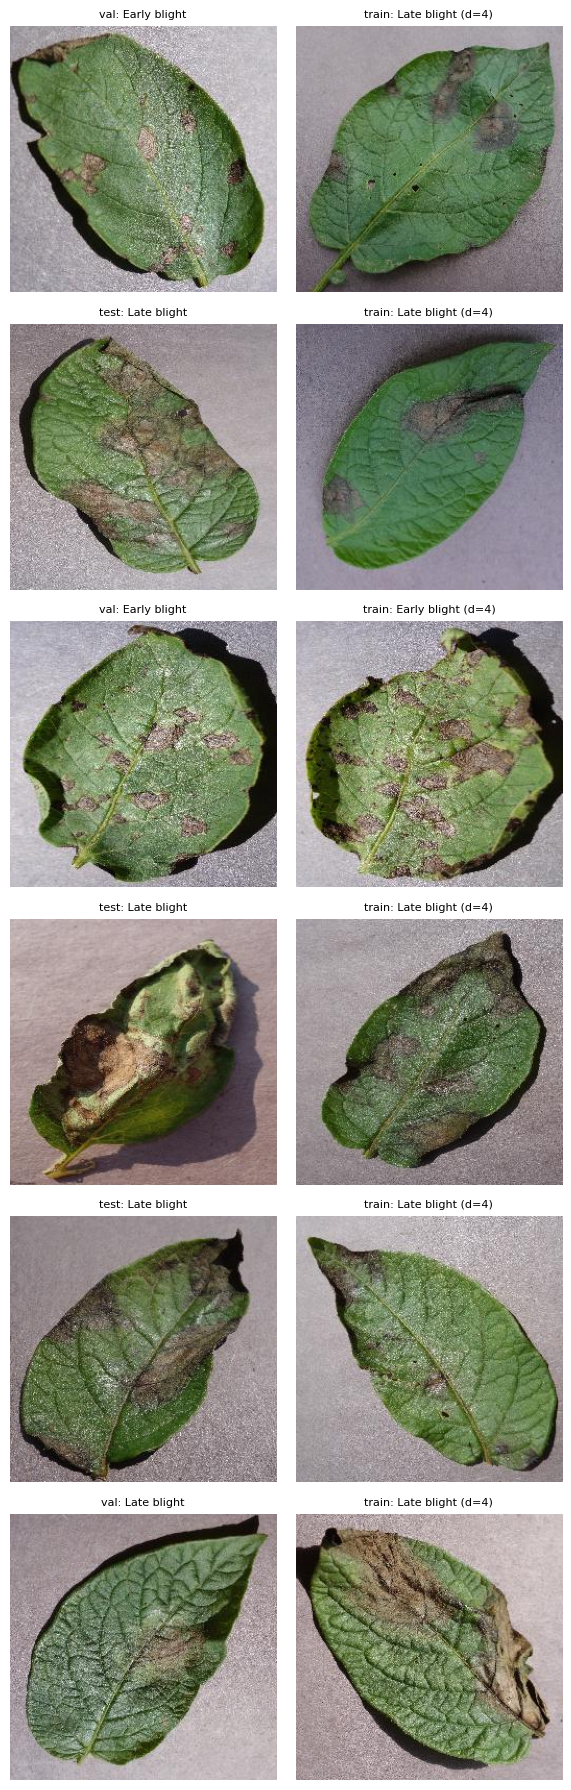

In [4]:
# Look at the 6 closest pairs side by side (eyeball check)
if RUN_LEAKAGE_CHECK:
    import matplotlib.pyplot as plt
    top = leak.head(6)
    fig, ax = plt.subplots(len(top), 2, figsize=(6, 3 * len(top)))
    for r, (_, row) in enumerate(top.iterrows()):
        ax[r, 0].imshow(Image.open(row.image));         ax[r, 0].set_title(f"{row.split}: {row.cls}", fontsize=8)
        ax[r, 1].imshow(Image.open(row.nearest_train)); ax[r, 1].set_title(f"train: {row.train_cls} (d={row.hamming})", fontsize=8)
        ax[r, 0].axis("off"); ax[r, 1].axis("off")
    plt.tight_layout(); plt.show()

## Step 2b: Build a leak-free training set
This cell removes every training image whose hash is within `LEAK_THRESHOLD` of **any** val or test image (in any flip/rotation), writes the result to a `_clean` folder, and points training at it. Val and test are not changed, so the val/test sets stay exactly as exported.

In [5]:
if RUN_LEAKAGE_CHECK and REMOVE_LEAKED:
    import shutil
    Q = np.concatenate([HQ["test"], HQ["val"]]).reshape(-1, 64)        # all val/test variants
    dmin = np.empty(len(Htr), dtype=int)
    for a in range(0, len(Htr), 256):                                  # chunked to keep memory small
        dmin[a:a+256] = (Htr[a:a+256, None, :] != Q[None, :, :]).sum(-1).min(1)
    drop = {train_items[i][0] for i in np.where(dmin <= LEAK_THRESHOLD)[0]}

    CLEAN = LOCAL_DATA + "_clean"
    if not os.path.exists(CLEAN):
        shutil.copytree(LOCAL_DATA, CLEAN)
        for p in drop:
            os.remove(p.replace(LOCAL_DATA, CLEAN, 1))
    LOCAL_DATA = CLEAN

    kept = pd.Series([c for p, c in train_items if p not in drop]).value_counts().sort_index()
    gone = pd.Series([c for p, c in train_items if p in drop]).value_counts().reindex(kept.index, fill_value=0)
    print(f"Removed {len(drop)} of {len(train_items)} training images; training now uses {LOCAL_DATA}")
    display(pd.DataFrame({"removed": gone, "kept": kept}))
    pd.Series(sorted(drop)).to_csv(os.path.join(OUT_DIR, "removed_train_images.csv"), index=False, header=["path"])

    # val/test overlap only affects checkpoint choice, but report it
    vt = (HQ["test"][:, None, None, 0, :] != HQ["val"][None, :, :, :]).sum(-1).min(-1).min(-1)
    print(f"Test images with a near-copy in val: {(vt <= LEAK_THRESHOLD).sum()} of {len(vt)}")

Removed 6 of 1506 training images; training now uses /content/data_potato_clean


,removed,kept
Early blight,1,699
Late blight,5,695
healthy,0,106


Test images with a near-copy in val: 0 of 324


## Step 3: Shared code (CBAM, data, model, training, evaluation)

In [6]:
import json, random, time
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, confusion_matrix, classification_report, log_loss)

print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
if DETERMINISTIC:
    tf.config.experimental.enable_op_determinism()

# ---------------- CBAM: same maths as the deployed model, now serialisable ----------------
@tf.keras.utils.register_keras_serializable(package="thesis")
class CBAM(layers.Layer):
    def __init__(self, ratio=8, spatial_kernel=7, **kwargs):
        super().__init__(**kwargs)
        self.ratio, self.spatial_kernel = ratio, spatial_kernel

    def build(self, input_shape):
        c = int(input_shape[-1])
        self.shared_dense_1 = layers.Dense(c // self.ratio, activation="relu")
        self.shared_dense_2 = layers.Dense(c)
        self.spatial_conv = layers.Conv2D(1, self.spatial_kernel, padding="same", activation="sigmoid")
        self.shared_dense_1.build((None, 1, 1, c))
        self.shared_dense_2.build((None, 1, 1, c // self.ratio))
        self.spatial_conv.build((None, None, None, 2))
        super().build(input_shape)

    def call(self, x):
        avg = tf.reduce_mean(x, axis=[1, 2], keepdims=True)
        mx = tf.reduce_max(x, axis=[1, 2], keepdims=True)
        ca = tf.sigmoid(self.shared_dense_2(self.shared_dense_1(avg)) + self.shared_dense_2(self.shared_dense_1(mx)))
        x = x * ca
        sa = self.spatial_conv(tf.concat([tf.reduce_mean(x, -1, keepdims=True),
                                          tf.reduce_max(x, -1, keepdims=True)], -1))
        return x * sa

    def get_config(self):
        return {**super().get_config(), "ratio": self.ratio, "spatial_kernel": self.spatial_kernel}

# ---------------- Architectures ----------------
A = tf.keras.applications
ARCHS = {
    "mobilenetv2":      (lambda: A.MobileNetV2(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3)),
                         A.mobilenet_v2.preprocess_input, False),
    "mobilenetv2_cbam": (lambda: A.MobileNetV2(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3)),
                         A.mobilenet_v2.preprocess_input, True),
    "mobilenetv1":      (lambda: A.MobileNet(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3)),
                         A.mobilenet.preprocess_input, False),
    "mobilenetv3large": (lambda: A.MobileNetV3Large(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3),
                                                    include_preprocessing=True),
                         lambda x: x, False),
}

def build_model(arch, num_classes):
    make_base, _, use_cbam = ARCHS[arch]
    base = make_base()
    base.trainable = False
    inp = layers.Input((*IMG_SIZE, 3))
    x = base(inp, training=False)                  # BatchNorm stays in inference mode, also when fine-tuning
    if use_cbam:
        x = CBAM(CBAM_RATIO, CBAM_KERNEL, name="cbam")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(DROPOUT)(x)
    out = layers.Dense(num_classes, activation="softmax")(x)
    return Model(inp, out, name=arch), base

# ---------------- Data: decoded once, cached in RAM, reshuffled per seed ----------------
_RAW = {}
def raw_split(split):
    if split not in _RAW:
        ds = tf.keras.utils.image_dataset_from_directory(
            os.path.join(LOCAL_DATA, split), image_size=IMG_SIZE, batch_size=None,
            label_mode="categorical", shuffle=False)
        names = ds.class_names
        ds = ds.map(lambda x, y: (tf.cast(tf.clip_by_value(tf.round(x), 0, 255), tf.uint8), y)).cache()
        n = sum(1 for _ in ds)                     # fills the cache
        _RAW[split] = (ds, names, n)
    return _RAW[split]

def make_ds(split, preprocess, seed=None):
    ds, names, n = raw_split(split)
    if seed is not None:                           # training split: shuffle with the run's seed
        ds = ds.shuffle(n, seed=seed, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).map(lambda x, y: (preprocess(tf.cast(x, tf.float32)), y),
                                  num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE), names

# ---------------- Crash-safe "best checkpoint" ----------------
class BestCheckpoint(tf.keras.callbacks.Callback):
    # Saves the model with the highest val_accuracy. The best value is kept on disk,
    # so after a crash a worse epoch can never overwrite a better checkpoint.
    def __init__(self, path, state_path):
        super().__init__()
        self.path, self.state_path = path, state_path
        self.best = json.load(open(state_path))["best_val_acc"] if os.path.exists(state_path) else -1.0

    def on_epoch_end(self, epoch, logs=None):
        v = float(logs["val_accuracy"])
        if v > self.best:
            self.best = v
            self.model.save(self.path, include_optimizer=False)
            json.dump({"best_val_acc": v, "best_epoch": epoch + 1}, open(self.state_path, "w"))
            print(f"  -> new best val_accuracy {v:.4f} at epoch {epoch + 1}, saved")

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [7]:
def train_one(arch, seed):
    run_dir = os.path.join(OUT_DIR, arch, f"seed_{seed}")
    os.makedirs(run_dir, exist_ok=True)
    result_file = os.path.join(run_dir, "results.json")
    if os.path.exists(result_file):
        print(f"[skip] {arch} seed {seed} already finished")
        return json.load(open(result_file))

    print(f"\n{'=' * 70}\n{arch} | seed {seed}\n{'=' * 70}")
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)           # Python, NumPy and TF in one call

    _, preprocess, _ = ARCHS[arch]
    train_ds, class_names = make_ds("train", preprocess, seed=seed)
    val_ds, _ = make_ds("val", preprocess)
    model, base = build_model(arch, len(class_names))

    best_path  = os.path.join(run_dir, "best.keras")
    state_path = os.path.join(run_dir, "best_state.json")
    stage1_w   = os.path.join(run_dir, "stage1_end.weights.h5")
    hist_path  = os.path.join(run_dir, "history.json")
    history = json.load(open(hist_path)) if os.path.exists(hist_path) else {}
    best_cb = BestCheckpoint(best_path, state_path)

    def fit(initial_epoch, epochs, lr, tag):
        model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="categorical_crossentropy", metrics=["accuracy"])
        cbs = [best_cb,
               tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
               tf.keras.callbacks.BackupAndRestore(os.path.join(run_dir, f"backup_{tag}"), delete_checkpoint=True)]
        h = model.fit(train_ds, validation_data=val_ds, initial_epoch=initial_epoch, epochs=epochs,
                      callbacks=cbs, verbose=1)
        for k, v in h.history.items():
            history.setdefault(k, []).extend([float(a) for a in v])
        json.dump(history, open(hist_path, "w"))

    t0 = time.perf_counter()
    # Stage 1: frozen backbone, epochs 1-10
    if os.path.exists(stage1_w):
        print("Stage 1 already done, loading its final weights")
        model.load_weights(stage1_w)
    else:
        fit(0, INITIAL_EPOCHS, INITIAL_LR, "stage1")
        model.save_weights(stage1_w)
    # Stage 2: whole backbone unfrozen, epochs 11-15 (exactly FINE_TUNE_EPOCHS)
    base.trainable = True
    fit(INITIAL_EPOCHS, INITIAL_EPOCHS + FINE_TUNE_EPOCHS, FINE_TUNE_LR, "stage2")
    train_minutes = (time.perf_counter() - t0) / 60

    res = evaluate_run(arch, seed, run_dir, best_path)
    res["train_minutes_this_session"] = round(train_minutes, 2)
    res["best_epoch"] = json.load(open(state_path))["best_epoch"]
    json.dump(res, open(result_file, "w"), indent=2)
    print(json.dumps({k: res[k] for k in ["test_acc", "test_macro_f1", "test_macro_auc", "best_epoch"]}, indent=2))
    return res


def evaluate_run(arch, seed, run_dir, best_path):
    _, preprocess, _ = ARCHS[arch]
    model = tf.keras.models.load_model(best_path)          # the SELECTED checkpoint
    out = {"model": arch, "seed": seed}
    for split in ["train", "val", "test"]:
        ds, names = make_ds(split, preprocess)
        y_true = np.concatenate([y.numpy() for _, y in ds]).argmax(1)
        prob = model.predict(ds, verbose=0)
        y_pred = prob.argmax(1)
        out[f"{split}_acc"] = 100 * accuracy_score(y_true, y_pred)
        if split != "test":
            continue
        np.save(os.path.join(run_dir, "test_probs.npy"), prob)
        np.save(os.path.join(run_dir, "test_true.npy"), y_true)
        p_m, r_m, f_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
        p_w, r_w, f_w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
        out.update(test_loss=float(log_loss(y_true, prob, labels=range(len(names)))),
                   test_balanced_acc=100 * balanced_accuracy_score(y_true, y_pred),
                   test_macro_precision=100 * p_m, test_macro_recall=100 * r_m, test_macro_f1=100 * f_m,
                   test_weighted_precision=100 * p_w, test_weighted_recall=100 * r_w, test_weighted_f1=100 * f_w,
                   test_macro_auc=float(roc_auc_score(y_true, prob, multi_class="ovr", average="macro")),
                   confusion_matrix=confusion_matrix(y_true, y_pred).tolist(), class_names=names)
        with open(os.path.join(run_dir, "classification_report.txt"), "w") as f:
            f.write(classification_report(y_true, y_pred, target_names=names, digits=4))
    # single-image latency, measured the same way for every model
    f = tf.function(lambda x: model(x, training=False))
    x = tf.zeros((1, *IMG_SIZE, 3))
    for _ in range(10): f(x)
    times = []
    for _ in range(100):
        t = time.perf_counter(); f(x).numpy(); times.append((time.perf_counter() - t) * 1000)
    out["latency_ms_median"] = float(np.median(times))
    return out

## Step 4: Run every model and seed
This is resume-safe: run it again after a disconnect and it carries on from where it stopped.

In [8]:
all_results = []
for arch in MODELS:
    for seed in SEEDS:
        all_results.append(train_one(arch, seed))

df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("confusion_matrix", "class_names")} for r in all_results])
df.to_csv(os.path.join(OUT_DIR, "all_seed_results.csv"), index=False)
display(df.round(2))


mobilenetv2 | seed 42
Found 1500 files belonging to 3 classes.
Found 322 files belonging to 3 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.3849 - loss: 1.3383  -> new best val_accuracy 0.5932 at epoch 1, saved
47/47 ━━━━━━━━━━━━━━━━━━━━ 19s 237ms/step - accuracy: 0.4180 - loss: 1.1970 - val_accuracy: 0.5932 - val_loss: 0.8453 - learning_rate: 1.0000e-04
Epoch 2/10
46/47 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.6037 - loss: 0.8943  -> new best val_accuracy 0.7050 at epoch 2, saved
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 117ms/step - accuracy: 0.6340 - loss: 0.8293 - val_accuracy: 0.7050 - val_loss: 0.6649 - learning_rate: 1.0000e-04
Epoch 3/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.7202 - loss: 0.6935  -> new best val_accuracy 0.8043 at epoch 3, saved
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 103ms/step - accuracy: 0.7187 - loss: 0.6891 - val_accuracy: 0.8043 - val_loss: 0.5488 - learning_rate: 1.0000e-04
Epo

,model,seed,train_acc,val_acc,test_acc,test_loss,test_balanced_acc,test_macro_precision,test_macro_recall,test_macro_f1,test_weighted_precision,test_weighted_recall,test_weighted_f1,test_macro_auc,latency_ms_median,train_minutes_this_session,best_epoch
0,mobilenetv2,42,96.07,96.27,94.75,0.17,92.72,88.82,92.72,90.51,95.20,94.75,94.89,1.00,5.12,2.82,12
1,mobilenetv2,123,95.80,95.34,94.75,0.21,92.72,90.92,92.72,91.77,94.87,94.75,94.79,1.00,5.03,2.72,11
2,mobilenetv2,202,96.53,96.27,95.68,0.16,93.39,91.57,93.39,92.43,95.77,95.68,95.71,1.00,5.32,2.67,11
3,mobilenetv2,456,96.20,95.34,95.99,0.19,93.61,93.62,93.61,93.61,96.00,95.99,95.99,0.99,5.17,2.72,11
4,mobilenetv2,789,95.73,94.41,95.06,0.21,92.94,92.01,92.94,92.46,95.12,95.06,95.08,0.99,7.18,2.70,11
5,mobilenetv2_cbam,42,99.67,96.58,97.53,0.06,93.56,96.88,93.56,95.08,97.51,97.53,97.48,1.00,7.30,2.67,9
6,mobilenetv2_cbam,123,99.00,97.83,96.91,0.07,95.44,95.50,95.44,95.44,96.99,96.91,96.91,1.00,13.13,2.75,7
7,mobilenetv2_cbam,202,98.60,97.20,96.30,0.09,93.83,94.90,93.83,94.34,96.29,96.30,96.28,1.00,5.23,2.67,6
8,mobilenetv2_cbam,456,99.73,97.52,97.53,0.06,95.89,95.92,95.89,95.88,97.57,97.53,97.53,1.00,7.44,2.95,10
9,mobilenetv2_cbam,789,99.53,97.20,97.53,0.06,94.72,95.77,94.72,95.23,97.51,97.53,97.51,1.00,13.40,2.69,9


## Step 5: Statistics for the thesis
- Mean ± SD and a t-based 95% CI per model
- **Paired** comparison on the same seeds: paired t-test, Wilcoxon signed-rank (with n = 5 its smallest possible p is 0.0625), 95% CI of the difference, Cohen's d_z
- **Minimum detectable difference**: how large the CBAM gain would have to be for p < 0.05 with this many seeds

The one-sample test against chance (14.29%) from the old notebook is removed because it carries no information.

In [9]:
from scipy import stats

df = pd.read_csv(os.path.join(OUT_DIR, "all_seed_results.csv"))
METRICS = ["test_acc", "test_macro_f1", "test_balanced_acc", "test_macro_auc", "test_loss"]

def mean_sd_ci(x):
    x = np.asarray(x, float); n = len(x); m, s = x.mean(), x.std(ddof=1)
    h = stats.t.ppf(0.975, n - 1) * s / np.sqrt(n)
    return m, s, m - h, m + h

summary = []
for arch, g in df.groupby("model"):
    for met in METRICS:
        m, s, lo, hi = mean_sd_ci(g[met])
        summary.append(dict(model=arch, metric=met, mean=m, sd=s, ci95=f"{lo:.2f} to {hi:.2f}"))
summary = pd.DataFrame(summary)
summary.to_csv(os.path.join(OUT_DIR, "summary_mean_sd_ci.csv"), index=False)
display(summary.round(4))

def paired(a_name, b_name, metric="test_acc"):
    a = df[df.model == a_name].set_index("seed")[metric]
    b = df[df.model == b_name].set_index("seed")[metric]
    seeds = sorted(set(a.index) & set(b.index)); a, b = a[seeds].values, b[seeds].values
    d = b - a; n = len(d)
    t, p = stats.ttest_rel(b, a)
    se = d.std(ddof=1) / np.sqrt(n); tc = stats.t.ppf(0.975, n - 1)
    w = stats.wilcoxon(b, a) if np.any(d != 0) else None
    return dict(comparison=f"{b_name} - {a_name}", metric=metric, n_seeds=n,
                mean_diff=d.mean(), sd_diff=d.std(ddof=1),
                ci95=f"{d.mean()-tc*se:.2f} to {d.mean()+tc*se:.2f}",
                t=t, p_ttest=p, p_wilcoxon=(w.pvalue if w else np.nan),
                cohens_dz=d.mean() / d.std(ddof=1),
                min_detectable_diff=tc * se,     # |mean diff| needed for p < 0.05 at this SD and n
                per_seed_diff=np.round(d, 2).tolist())

if {"mobilenetv2", "mobilenetv2_cbam"} <= set(df.model):
    comp = pd.DataFrame([paired("mobilenetv2", "mobilenetv2_cbam", m) for m in ["test_acc", "test_macro_f1"]])
    comp.to_csv(os.path.join(OUT_DIR, "paired_comparison.csv"), index=False)
    display(comp.round(4))
    r = comp.iloc[0]
    print(f"\nThesis sentence: Across {r.n_seeds} paired seeds, adding CBAM changed test accuracy by "
          f"{r.mean_diff:+.2f} pp (95% CI {r.ci95} pp; paired t = {r.t:.2f}, p = {r.p_ttest:.3f}; "
          f"Wilcoxon p = {r.p_wilcoxon:.3f}; d_z = {r.cohens_dz:.2f}). With this variability, a difference of about "
          f"{r.min_detectable_diff:.1f} pp would be needed to reach significance.")

,model,metric,mean,sd,ci95
0,mobilenetv1,test_acc,97.5309,0.5346,96.87 to 98.19
1,mobilenetv1,test_macro_f1,94.9886,1.0152,93.73 to 96.25
2,mobilenetv1,test_balanced_acc,97.9889,0.7416,97.07 to 98.91
3,mobilenetv1,test_macro_auc,0.9983,0.0004,1.00 to 1.00
4,mobilenetv1,test_loss,0.0977,0.0123,0.08 to 0.11
5,mobilenetv2,test_acc,95.2469,0.5607,94.55 to 95.94
6,mobilenetv2,test_macro_f1,92.1575,1.1339,90.75 to 93.57
7,mobilenetv2,test_balanced_acc,93.0778,0.4037,92.58 to 93.58
8,mobilenetv2,test_macro_auc,0.9948,0.0021,0.99 to 1.00
9,mobilenetv2,test_loss,0.1857,0.0210,0.16 to 0.21


,comparison,metric,n_seeds,mean_diff,sd_diff,ci95,t,p_ttest,p_wilcoxon,cohens_dz,min_detectable_diff,per_seed_diff
0,mobilenetv2_cbam - mobilenetv2,test_acc,5,1.9136,0.8564,0.85 to 2.98,4.9961,0.0075,0.0625,2.2343,1.0634,"[2.78, 2.16, 0.62, 1.54, 2.47]"
1,mobilenetv2_cbam - mobilenetv2,test_macro_f1,5,3.0374,1.0793,1.70 to 4.38,6.2930,0.0033,0.0625,2.8143,1.3401,"[4.56, 3.67, 1.91, 2.27, 2.77]"



Thesis sentence: Across 5 paired seeds, adding CBAM changed test accuracy by +1.91 pp (95% CI 0.85 to 2.98 pp; paired t = 5.00, p = 0.008; Wilcoxon p = 0.062; d_z = 2.23). With this variability, a difference of about 1.1 pp would be needed to reach significance.


In [10]:
# Optional: Friedman test across all models (only if you ran 3 or more models)
if df.model.nunique() >= 3:
    piv = df.pivot(index="seed", columns="model", values="test_acc").dropna()
    print(stats.friedmanchisquare(*[piv[c] for c in piv.columns]))
    display(piv.round(2))

FriedmanchisquareResult(statistic=np.float64(12.79591836734693), pvalue=np.float64(0.005099387257850142))


model,mobilenetv1,mobilenetv2,mobilenetv2_cbam,mobilenetv3large
seed,,,,
42,97.22,94.75,97.53,95.06
123,97.22,94.75,96.91,95.37
202,98.46,95.68,96.30,93.83
456,97.22,95.99,97.53,96.30
789,97.53,95.06,97.53,96.91


## Step 6: Figures (saved to `OUT_DIR/figures`)

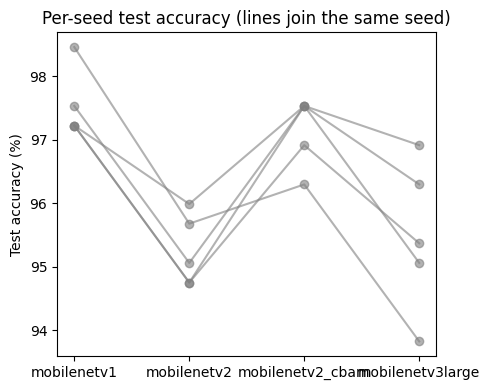

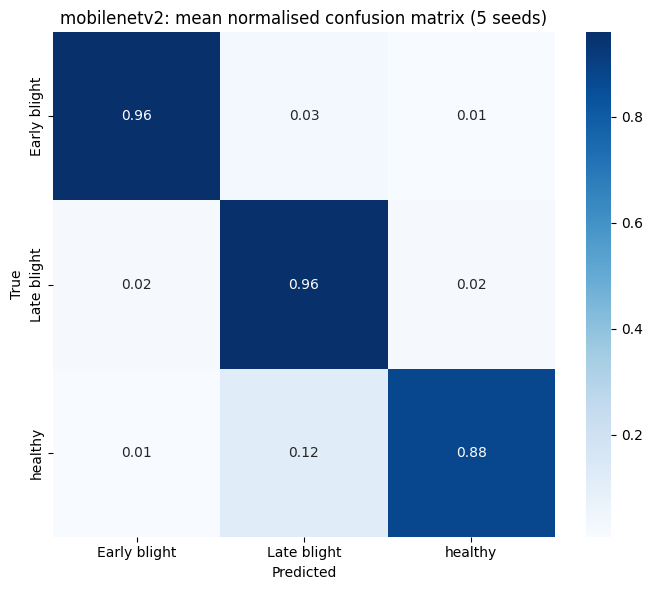

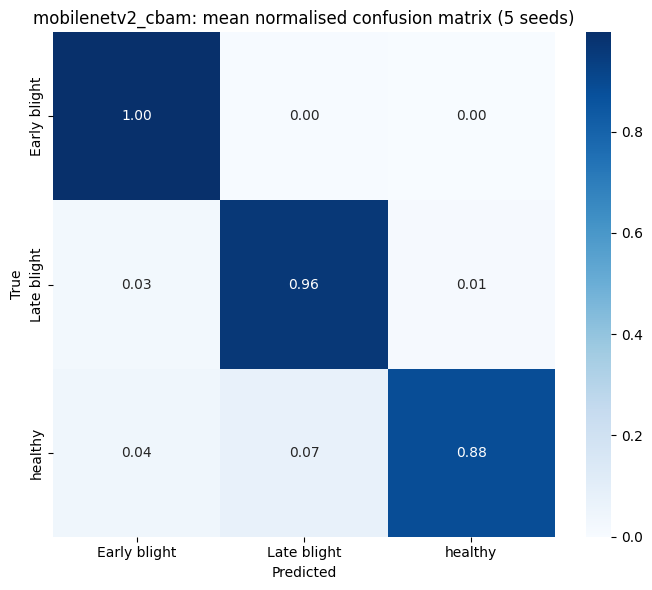

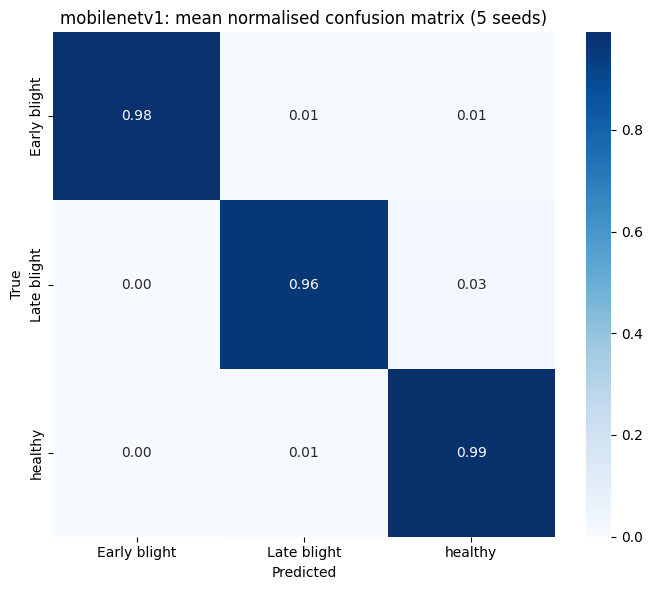

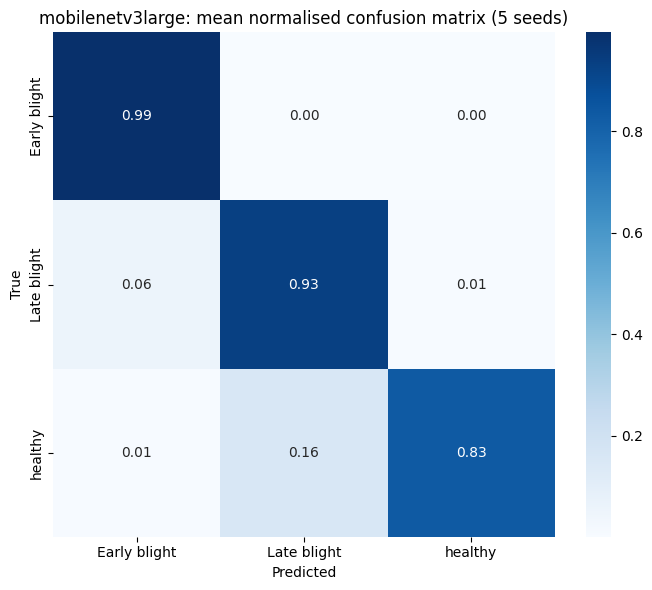

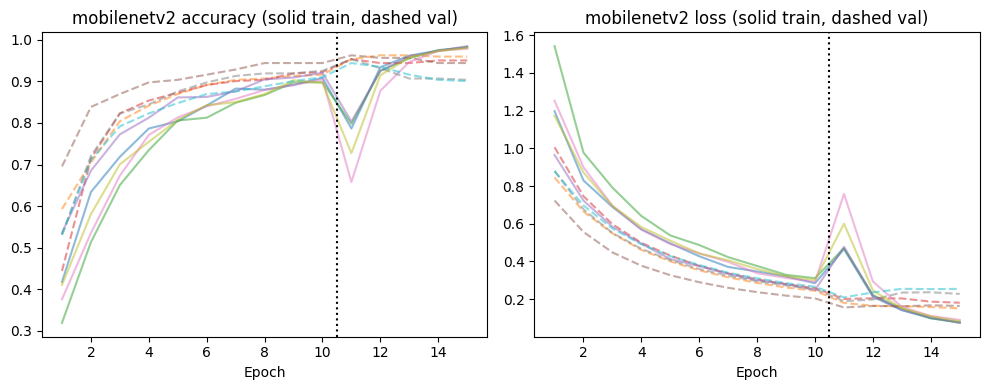

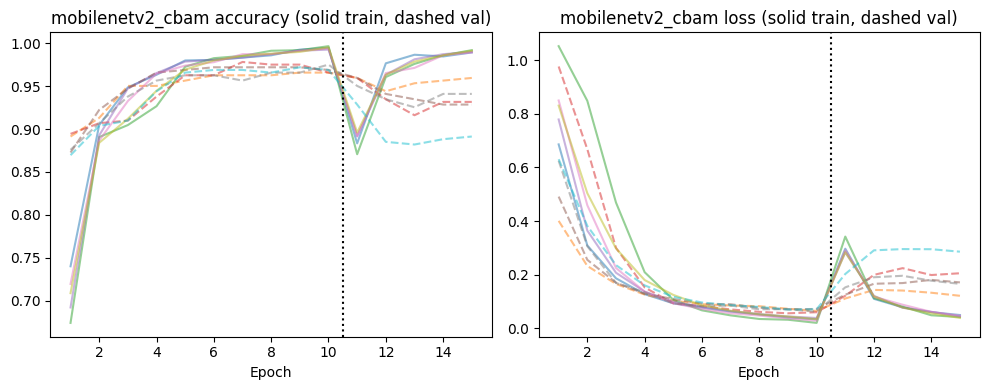

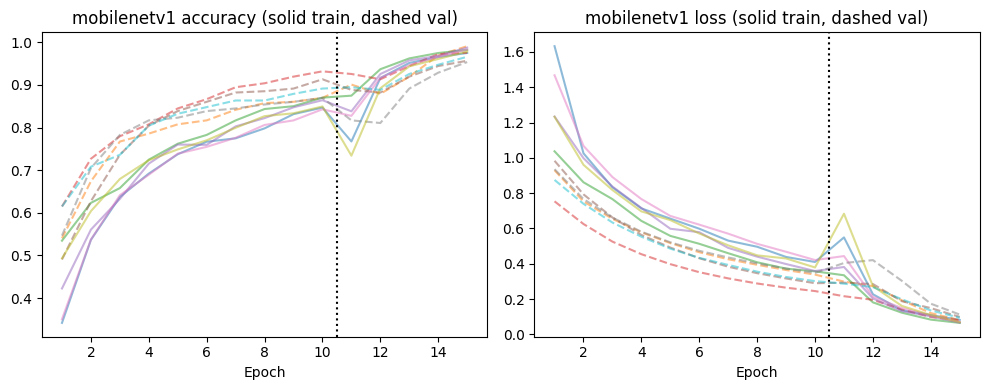

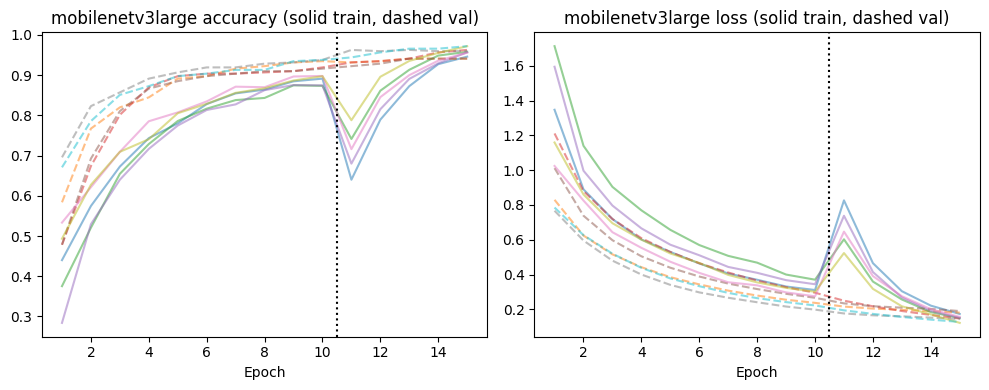

In [11]:
import matplotlib.pyplot as plt, seaborn as sns
fig_dir = os.path.join(OUT_DIR, "figures"); os.makedirs(fig_dir, exist_ok=True)

# Per-seed accuracy, paired lines
plt.figure(figsize=(5, 4))
piv = df.pivot(index="seed", columns="model", values="test_acc")
for s, row in piv.iterrows():
    plt.plot(range(len(row)), row.values, "o-", color="grey", alpha=.6)
plt.xticks(range(len(piv.columns)), piv.columns); plt.ylabel("Test accuracy (%)")
plt.title("Per-seed test accuracy (lines join the same seed)")
plt.tight_layout(); plt.savefig(os.path.join(fig_dir, "paired_seeds.png"), dpi=300); plt.show()

# Mean row-normalised confusion matrix per model
for arch in df.model.unique():
    runs = [r for r in all_results if r["model"] == arch]
    cms = [np.array(r["confusion_matrix"], float) for r in runs]
    cm = np.mean([c / c.sum(1, keepdims=True) for c in cms], axis=0)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=runs[0]["class_names"], yticklabels=runs[0]["class_names"])
    plt.title(f"{arch}: mean normalised confusion matrix ({len(runs)} seeds)")
    plt.ylabel("True"); plt.xlabel("Predicted"); plt.tight_layout()
    plt.savefig(os.path.join(fig_dir, f"cm_{arch}.png"), dpi=300); plt.show()

# Learning curves (stage 1 + stage 2 joined, dashed line = unfreeze)
for arch in df.model.unique():
    plt.figure(figsize=(10, 4))
    for i, key in enumerate(["accuracy", "loss"]):
        plt.subplot(1, 2, i + 1)
        for seed in SEEDS:
            hp = os.path.join(OUT_DIR, arch, f"seed_{seed}", "history.json")
            if os.path.exists(hp):
                h = json.load(open(hp))
                plt.plot(range(1, len(h[key]) + 1), h[key], alpha=.5)
                plt.plot(range(1, len(h["val_" + key]) + 1), h["val_" + key], "--", alpha=.5)
        plt.axvline(INITIAL_EPOCHS + .5, color="k", ls=":"); plt.title(f"{arch} {key} (solid train, dashed val)")
        plt.xlabel("Epoch")
    plt.tight_layout(); plt.savefig(os.path.join(fig_dir, f"curves_{arch}.png"), dpi=300); plt.show()